# Determination of the critical porperties of a 2D Ising Model on honeycomb lattice

In [34]:
# LIBRARIES
import Ising_tools
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

In [8]:
# SPIN MATRIX POPULATION

D = 2       # dimension of the lattice
L = 50      # size of the lattice
spin_matrix = np.random.choice([-1, 1], size=(L, L))

In [9]:
'''# METROPOLIS STEPS

T = np.arange(0.1, 5.1, 0.1)  # temperature range
metropolis_steps = L**2               # number of Metropolis steps

for temperature in tqdm(T):
    for i in range(metropolis_steps):
        spin_matrix = Ising_tools.metropolis(spin_matrix, temperature)
    pass'''

'# METROPOLIS STEPS\n\nT = np.arange(0.1, 5.1, 0.1)  # temperature range\nmetropolis_steps = L**2               # number of Metropolis steps\n\nfor temperature in tqdm(T):\n    for i in range(metropolis_steps):\n        spin_matrix = Ising_tools.metropolis(spin_matrix, temperature)\n    pass'

100%|██████████| 1000/1000 [04:50<00:00,  3.44it/s]


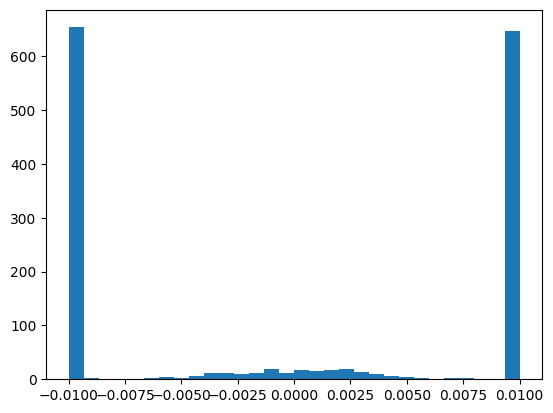

In [ ]:
D = 2       # dimension of the lattice
L = 10      # size of the lattice

n_simulation = 1000  # number of simulations for averaging
T = 0.8
n_sweep = 100
metropolis_steps = 100 * L**2               # number of Metropolis steps
m_samples = np.zeros(n_simulation)  # array to store magnetization samples

for i in tqdm(range(n_simulation)):
    spin_matrix = np.random.choice([-1, 1], size=(L, L))
    for _ in range(metropolis_steps):
        spin_matrix = Ising_tools.metropolis(spin_matrix, T)
    m_samples[i] = Ising_tools.magnetization(spin_matrix)

plt.hist(m_samples, bins=30, density=True)
plt.title(f'Magnetization Distribution at T={T}')
plt.xlabel('Magnetization')
plt.ylabel('Density')
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
from time import time

@njit
def metropolis_numba(spin_matrix, T, n_steps):
    """
    Esegue n_steps di Metropolis compilati in codice macchina.
    Modifica la matrice direttamente in-place per la massima efficienza.
    """
    L = spin_matrix.shape[0]
    
    for _ in range(n_steps):
        rand_i = np.random.randint(0, L)
        rand_j = np.random.randint(0, L)
        rand_spin = spin_matrix[rand_i, rand_j]

        # Vicini con condizioni al contorno periodiche su griglia quadrata
        if rand_j % 2 == 0:     # for rand_j even, the neighbours are (i-1,j) , (i,j+-1)
                neighbours_sum = (spin_matrix[(rand_i - 1) % L, rand_j] +
                             spin_matrix[rand_i, (rand_j - 1) % L] +
                             spin_matrix[rand_i, (rand_j + 1) % L])
        else:                   # for rand_j odd, the neighbours are (i+1,j) , (i,j+-1)
            neighbours_sum = (spin_matrix[(rand_i + 1) % L, rand_j] +
                            spin_matrix[rand_i, (rand_j - 1) % L] +
                            spin_matrix[rand_i, (rand_j + 1) % L])

        dE = 2 * rand_spin * neighbours_sum

        if dE <= 0 or np.random.rand() < np.exp(-dE / T):
            spin_matrix[rand_i, rand_j] *= -1

    return spin_matrix

def magnetization_numba(spin_matrix):
    return np.sum(spin_matrix) / (spin_matrix.shape[0] ** 2)

# --- PARAMETRI ---
t0 = time()
L = 10
n_simulation = 1000
T = 0.8
metropolis_steps = 50 * (L ** 2)

m_samples = np.zeros(n_simulation)

# Warm-up della compilazione JIT
spin_dummy = np.random.choice(np.array([-1, 1]), size=(L, L))
_ = metropolis_numba(spin_dummy, T, 1)

# Esecuzione principale
for i in range(n_simulation):
    spin_matrix = np.random.choice(np.array([-1, 1]), size=(L, L))
    metropolis_numba(spin_matrix, T, metropolis_steps)
    m_samples[i] = magnetization_numba(spin_matrix)

t1 = time()
print(f"Tempo di esecuzione con Numba: {t1 - t0:.2f} secondi")
plt.hist(m_samples, bins=30, density=True)
plt.title(f'Magnetization Distribution at T={T} (Numba Accelerated)')
plt.xlabel('Magnetization')
plt.ylabel('Density')
plt.show()

KeyboardInterrupt: 